# Fading Memory Systems, Volterra Series and CNNs – Warm-up

**Part 1:** What is a fading memory system and how can we find out whether (and how much) memory a system has?
**Part 2:** Volterra series – model and identify a nonlinear system with memory.
**Part 3:** Volterra as a special case of a CNN.
**Part 4:** Coherence and bispectrum – linear or nonlinear?

Needs `numpy`, `scipy`, `matplotlib`, `scikit-learn` and `stingray`.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter
from math import comb
from sklearn.feature_selection import mutual_info_regression

rng = np.random.default_rng(0)
plt.rcParams['figure.figsize'] = (12, 4)

## Part 1 – Does the system have memory?

A system has **memory** if the output now depends on past inputs: $y[n] = f(x[n], x[n-1], x[n-2], \dots)$.
It has **fading memory** if the influence of old inputs dies out – the system *forgets*: two inputs that differ only far in the past give (almost) the same output now.

| System | Memory | Forgets? |
|---|---|---|
| $y[n]=x[n]^2$ | none | – |
| FIR filter | finite | yes |
| Recursive filter $y[n]=x[n]+0.8\,y[n-1]$ | infinite | yes, slowly |
| Peak-hold $y[n]=\max_{k\le n} x[k]$ | infinite | no |

### Test 1: nudge the input (we can drive the system)
Feed two inputs that differ **only at one instant** $n_0$ and watch how long the outputs differ. The length of the tail is the memory.

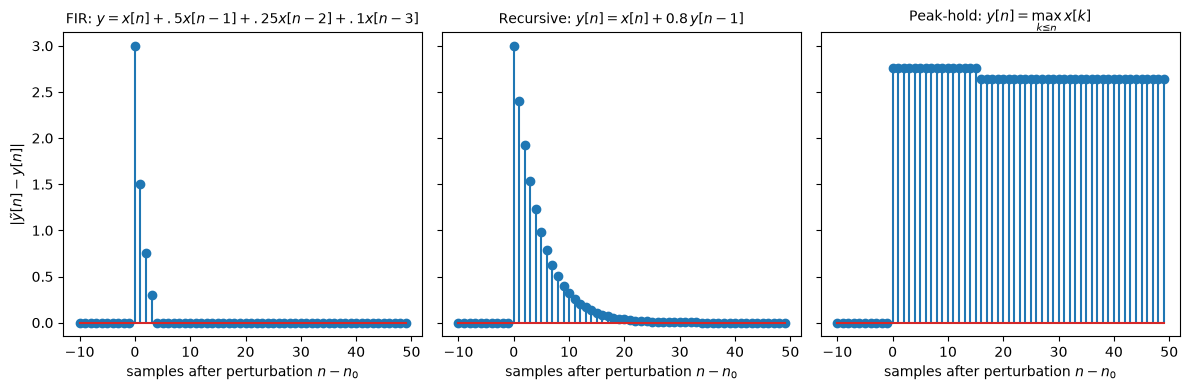

In [ ]:
systems = {
    'FIR: $y=x[n]+.5x[n-1]+.25x[n-2]+.1x[n-3]$': lambda x: lfilter([1, .5, .25, .1], 1, x),
    r'Recursive: $y[n]=x[n]+0.8\,y[n-1]$':             lambda x: lfilter([1], [1, -0.8], x),
    r'Peak-hold: $y[n]=\max_{k\leq n} x[k]$':     lambda x: np.maximum.accumulate(x),
}

N, n0 = 60, 10
x = rng.uniform(-1, 1, N)
x_pert = x.copy()
x_pert[n0] += 3.0          # differ only at n0

fig, axs = plt.subplots(1, 3, sharey=True)
for ax, (name, f) in zip(axs, systems.items()):
    ax.stem(np.arange(N) - n0, np.abs(f(x_pert) - f(x)))
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('samples after perturbation $n-n_0$')
axs[0].set_ylabel(r'$|\tilde y[n]-y[n]|$')
plt.tight_layout()

FIR: the difference vanishes after 4 samples (finite memory). Recursive filter: shrinks like $0.8^k$ (fades). Peak-hold: never goes away (does not forget).

### Test 2: correlation (we only have recorded data)
Feed white noise and correlate the output with delayed inputs: $r_{yx}[k]$ = average of $y[n]\,x[n-k]$. If $y$ depends on $x[n-k]$, we expect a bar at lag $k$. The grey band marks values that cannot be told apart from zero.
**But:** for nonlinear systems this can be blind. Below, $y[n] = x[n-1]^2 + x[n]\,x[n-3]$ clearly has memory, yet all bars are ≈ 0.
Correlating with *products* $x[n-i]\,x[n-j]$ reveals it – this is the idea behind the Volterra series in Part 2.

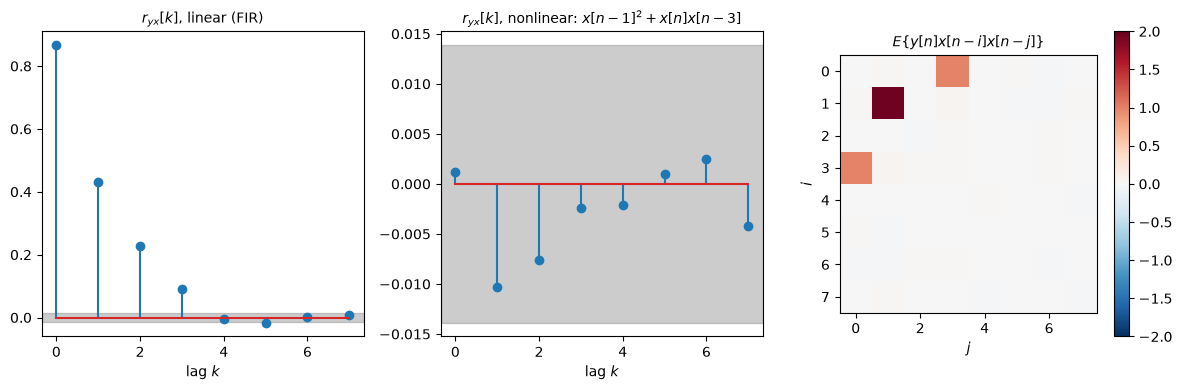

In [ ]:
N, K = 20000, 8
x = rng.standard_normal(N)
systems = {
    'linear (FIR)':                 lfilter([1, .5, .25, .1], 1, x),
    'nonlinear: $x[n-1]^2+x[n]x[n-3]$': np.r_[0, x[:-1]]**2 + x * np.r_[0, 0, 0, x[:-3]],
}

def xcorr(y, x, K):
    # normalized r_yx[k] = E{y[n] x[n-k]}, k = 0..K-1
    y = (y - y.mean()) / y.std()
    return np.array([np.mean(y[k:] * x[:len(x) - k]) for k in range(K)])

fig, axs = plt.subplots(1, 3)
for ax, (name, y) in zip(axs, systems.items()):
    ax.stem(xcorr(y, x, K))
    ax.axhspan(-1.96 / np.sqrt(N), 1.96 / np.sqrt(N), color='gray', alpha=.4)  # 95% band for "zero"
    ax.set_title(f'$r_{{yx}}[k]$, {name}', fontsize=10); ax.set_xlabel('lag $k$')

# second-order cross-correlation of the nonlinear system
y = systems['nonlinear: $x[n-1]^2+x[n]x[n-3]$']
X = np.stack([np.r_[np.zeros(k), x[:N - k]] for k in range(K)], 1)   # X[n, k] = x[n-k]
R2 = (X * (y - y.mean())[:, None]).T @ X / N                          # R2[i,j] = E{y x[n-i] x[n-j]}
im = axs[2].imshow(R2, cmap='RdBu_r', vmin=-2, vmax=2)
axs[2].set_title(r'$E\{y[n]x[n-i]x[n-j]\}$', fontsize=10); axs[2].set_xlabel('$j$'); axs[2].set_ylabel('$i$')
plt.colorbar(im, ax=axs[2]); plt.tight_layout()

The second-order map lights up at $(1,1)$ and $(0,3)/(3,0)$ – exactly the products in the system. Memory = 3 samples.

### Test 3: mutual information (catches *any* dependence)
Correlation only measures *linear* dependence. **Mutual information** (MI) measures *any* dependence between two random variables:

$$I(X;Y) = \iint p(x,y)\,\log\frac{p(x,y)}{p(x)\,p(y)}\,dx\,dy \;\ge 0$$

* Read it as: *how much does knowing $X$ reduce my uncertainty about $Y$?* (in nats).
* $I(X;Y)=0$ **if and only if** $X$ and $Y$ are independent – not just uncorrelated.
* For jointly Gaussian variables $I = -\tfrac12\log(1-\rho^2)$, so for linear systems it tells the same story as correlation.

To find memory, compute $I(y[n];\,x[n-k])$ for each lag $k$. We use the k-nearest-neighbour estimator of Kraskov et al. (2004) from scikit-learn (`mutual_info_regression`), which works directly on samples without binning.
MI estimates are never exactly zero, so we get a threshold by **shuffling** $y$ (destroys any dependence) and taking the largest MI we see.

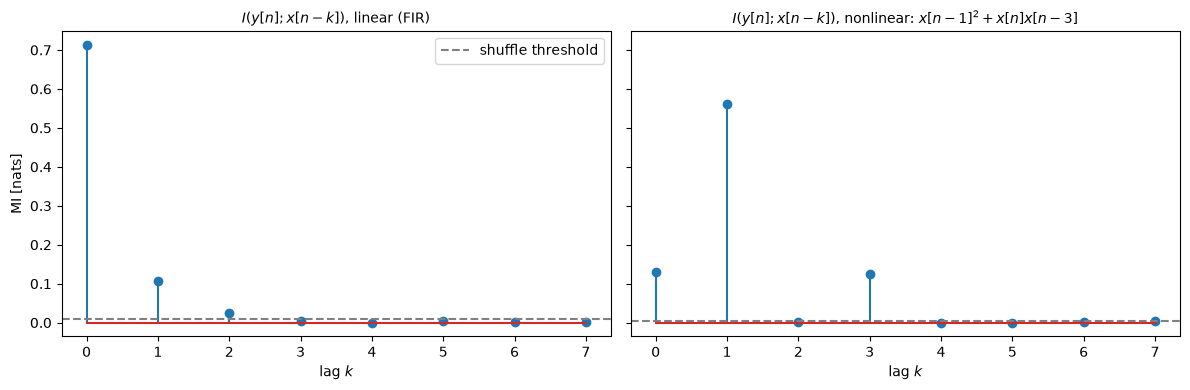

In [ ]:
def mi_lags(y, x, K, n_shuffle=5, n_neighbors=10):
    # MI between y[n] and x[n-k], k = 0..K-1 (kNN estimator, nats), plus a threshold from shuffled y
    X = np.stack([np.r_[np.zeros(k), x[:len(x) - k]] for k in range(K)], 1)
    mi = mutual_info_regression(X, y, n_neighbors=n_neighbors, random_state=0)
    null = [mutual_info_regression(X, rng.permutation(y), n_neighbors=n_neighbors, random_state=0)
            for _ in range(n_shuffle)]
    return mi, np.max(null)

fig, axs = plt.subplots(1, 2, sharey=True)
for ax, (name, y) in zip(axs, systems.items()):
    mi, thr = mi_lags(y, x, K)
    ax.stem(mi)
    ax.axhline(thr, color='gray', ls='--', label='shuffle threshold')
    ax.set_title(f'$I(y[n];x[n-k])$, {name}', fontsize=10); ax.set_xlabel('lag $k$')
axs[0].set_ylabel('MI [nats]'); axs[0].legend(); plt.tight_layout()

For the nonlinear system, where the correlation saw nothing, MI finds lags 0, 1 and 3 – exactly the samples the system uses – and nothing at lag 2.

**Discuss:** for the linear FIR, the weak tap at lag 3 (coefficient 0.1) falls below the threshold although correlation finds it: MI needs more data than correlation and is slower to estimate. It also looks at one lag at a time: a system whose output depends only on a *combination* of two inputs, where neither input alone carries information (e.g. $y=\mathrm{sign}(x[n]\,x[n-3])$), would still be missed.

## Part 2 – Volterra series

Idea: model the output as a polynomial of the last $M$ input samples – an FIR filter plus all products of two past samples (triples etc. for higher orders):

$$y[n] = h_0 + \sum_{k=0}^{M-1} h_1[k]\,x[n-k] + \sum_{k=0}^{M-1}\sum_{l=k}^{M-1} h_2[k,l]\,x[n-k]\,x[n-l]$$

The model is nonlinear in $x$ but **linear in the coefficients** $h$ → we fit it with ordinary least squares.

### Example: fit a 2nd-order Volterra model
True system: filter $v = h * x$ with $h = [1, 0.6, 0.3, 0.1]$, then $y = v + 0.5\,v^2$ + noise. Its exact coefficients are $h_1 = h$ and $h_2[k,l] = 0.5\,h[k]\,h[l]$.

**How the kernel estimation works**

1. **Write the model as a linear regression.** Collect all terms of the model at time $n$ in one row vector $\varphi[n]$ and all coefficients in one vector $\theta$, so that $y[n] = \varphi[n]^T\theta$. For $M=2$:
$$\varphi[n] = [\,1,\; x[n],\; x[n-1],\; x[n]^2,\; x[n]x[n-1],\; x[n-1]^2\,], \qquad \theta = [\,h_0,\; h_1[0],\; h_1[1],\; h_2[0,0],\; h_2[0,1],\; h_2[1,1]\,]$$
2. **Stack all time steps** into a matrix $\Phi$ (one row per $n$): $\;y = \Phi\,\theta + \text{noise}$. This is `volterra_features`.
3. **Least squares:** $\hat\theta = \arg\min_\theta \|y - \Phi\theta\|^2 = (\Phi^T\Phi)^{-1}\Phi^T y$. `np.linalg.lstsq` solves this (numerically stable, no explicit inverse).
4. **Sort $\hat\theta$ back into kernels.** Since $x[n-k]x[n-l] = x[n-l]x[n-k]$, only pairs $k \le l$ get a coefficient (a triangular kernel). For plotting we split each off-diagonal value evenly between $(k,l)$ and $(l,k)$ to get the usual symmetric $h_2$. This is `to_kernels`.

Two conditions: the input must excite all products (random broadband input does), and we need many more samples than coefficients (here 2000 samples vs. $1 + 6 + 21 = 28$ coefficients for $M=6$).

test NMSE = 0.0151  (noise floor = 0.0155)


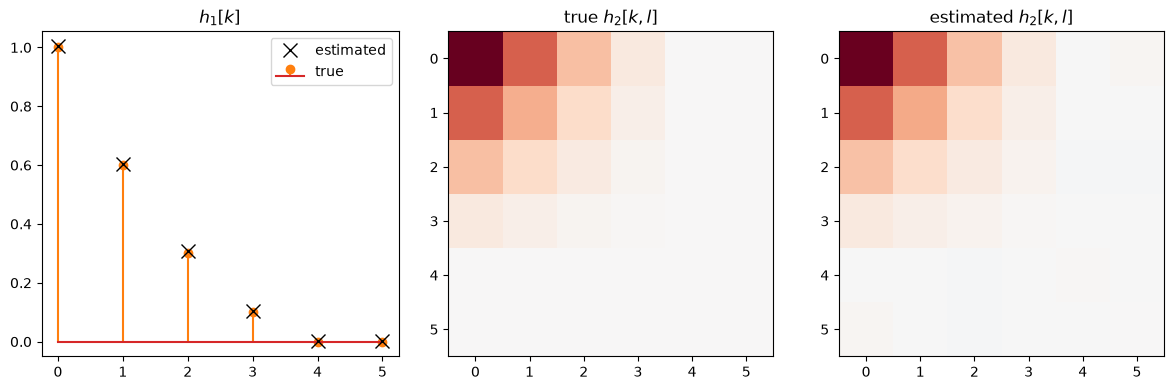

In [ ]:
def filter_then_square(x, h=np.array([1, .6, .3, .1])):
    v = lfilter(h, 1, x)                 # linear FIR filter ...
    return v + 0.5 * v**2                # ... followed by a static nonlinearity

def volterra_features(x, M):
    # regression matrix Phi: one row per time step n, columns [1, x[n-k], x[n-k]x[n-l] (k<=l)]
    X = np.stack([np.r_[np.zeros(k), x[:len(x) - k]] for k in range(M)], 1)   # X[n, k] = x[n-k] (zeros before start)
    i, j = np.triu_indices(M)                                                # all lag pairs with i <= j
    return np.hstack([np.ones((len(x), 1)),   # h0 (constant)
                      X,                      # h1: linear terms
                      X[:, i] * X[:, j]])     # h2: all products of two past samples

def to_kernels(theta, M):
    h1 = theta[1:M + 1]                                      # skip h0, next M values are h1[0..M-1]
    H2 = np.zeros((M, M)); H2[np.triu_indices(M)] = theta[M + 1:]   # remaining values fill the upper triangle
    return h1, (H2 + H2.T) / 2          # triangular -> symmetric: split off-diagonal values in half

# data: random input on [-1, 1] excites all lag products
noise_std = 0.1
x_tr, x_te = rng.uniform(-1, 1, 2000), rng.uniform(-1, 1, 500)
y_tr = filter_then_square(x_tr) + noise_std * rng.standard_normal(len(x_tr))
y_te = filter_then_square(x_te) + noise_std * rng.standard_normal(len(x_te))

# least-squares identification: solve y = Phi @ theta for theta
M = 6                                                       # model memory (true memory is 4)
Phi = volterra_features(x_tr, M)                            # shape (2000, 28)
theta = np.linalg.lstsq(Phi, y_tr, rcond=None)[0]           # minimizes ||y - Phi theta||^2
h1, H2 = to_kernels(theta, M)

h_true = np.r_[1, .6, .3, .1, 0, 0]
fig, axs = plt.subplots(1, 3)
axs[0].stem(h_true, linefmt='C1-', markerfmt='C1o', label='true')
axs[0].plot(h1, 'kx', ms=10, label='estimated'); axs[0].legend(); axs[0].set_title('$h_1[k]$')
for ax, K2, t in zip(axs[1:], [0.5 * np.outer(h_true, h_true), H2], ['true $h_2[k,l]$', 'estimated $h_2[k,l]$']):
    ax.imshow(K2, cmap='RdBu_r', vmin=-.5, vmax=.5); ax.set_title(t)
plt.tight_layout()

y_hat = volterra_features(x_te, M) @ theta     # prediction on unseen test data
print(f'test NMSE = {np.mean((y_hat - y_te)**2) / np.var(y_te):.4f}  (noise floor = {noise_std**2 / np.var(y_te):.4f})')

### Model order selection = memory estimation
Fit models with increasing memory $M$ and watch the test error: it drops until $M$ reaches the true memory (4) and then stays at the noise floor. The smallest such $M$ is our memory estimate.

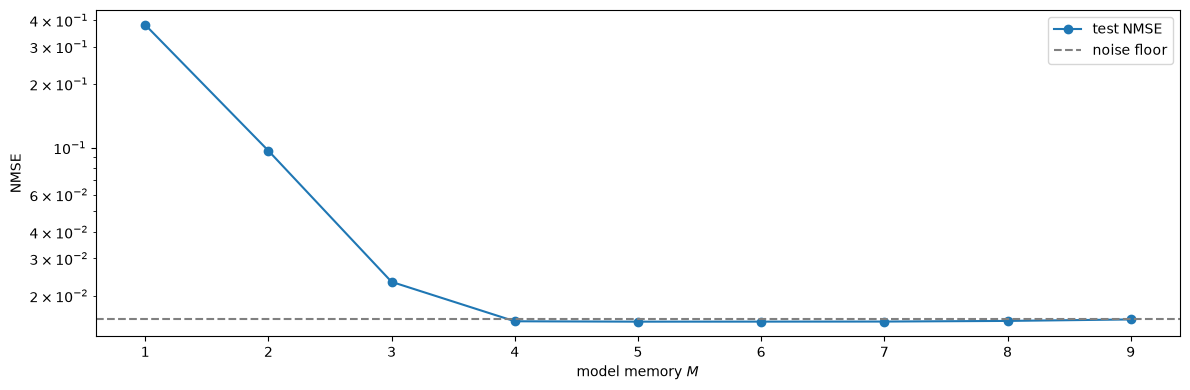

In [ ]:
Ms = range(1, 10)
nmse = []
for M in Ms:
    th = np.linalg.lstsq(volterra_features(x_tr, M), y_tr, rcond=None)[0]
    nmse.append(np.mean((volterra_features(x_te, M) @ th - y_te)**2) / np.var(y_te))

plt.semilogy(Ms, nmse, 'o-', label='test NMSE')
plt.axhline(noise_std**2 / np.var(y_te), color='gray', ls='--', label='noise floor')
plt.xlabel('model memory $M$'); plt.ylabel('NMSE'); plt.legend(); plt.tight_layout()

### The catch: number of parameters
A Volterra model of order $P$ with memory $M$ has $\binom{M+P}{P}$ coefficients. This explodes quickly – one motivation for compact models like **CNNs** in the next notebooks.

In [ ]:
for P in [2, 3, 5]:
    print(f'P={P}: ' + ', '.join(f'M={M}: {comb(M + P, P)}' for M in [5, 10, 20, 50]))

P=2: M=5: 21, M=10: 66, M=20: 231, M=50: 1326
P=3: M=5: 56, M=10: 286, M=20: 1771, M=50: 23426
P=5: M=5: 252, M=10: 3003, M=20: 53130, M=50: 3478761


**Try yourself**
* Swap the order: square first, then filter (`lfilter(h, 1, x + 0.5*x**2)`) – what structure does $h_2$ have now?
* Use `np.tanh(3*v)` as nonlinearity – how well does the 2nd-order model do? Why?
* Feed the systems from Test 2 through `volterra_features` and compare the estimated $h_2$ with the second-order cross-correlation map.

## Part 4 – Linear or nonlinear? Correlation, coherence and bispectrum

Given only data: is a linear model enough, or is the system nonlinear? We compare the two fading-memory systems of notebook 5.1:

* `linsys`: a linear Butterworth low-pass (IIR, infinite but fading memory),
* `system`: a deterministic nonlinearity with memory 5,

using the **autocorrelation**, **PSD / cross-spectrum / coherence** (second order) and the **bispectrum** (third order).

In [ ]:
import scipy.signal as ssig
from scipy.linalg import hankel
from stingray.bispectrum import Bispectrum
from stingray.lightcurve import Lightcurve

def linsys(x, order=3, cutoff=0.3):
    """Linear, causal IIR filter (Butterworth low-pass)."""
    b, a = ssig.butter(order, cutoff)
    return ssig.lfilter(b, a, x)

def system(x):
    """Deterministic, fading memory nonlinearity with memory 5 (zero-padded at the start)."""
    mem_depth = 5
    weights = np.array([1.1, 4.5, 1.4, 1.3, 3.2])
    padded_x = np.concatenate((np.zeros(mem_depth - 1,), x))
    X = hankel(padded_x[:mem_depth], padded_x[mem_depth-1:])   # column n = [x[n-4], ..., x[n]]
    X[0,:] = (X[0,:] - X[4,:])**2
    X[1,:] = np.exp(-np.abs(X[1,:] - X[2,:]))
    X[2,:] = np.sqrt(np.abs(X[2,:]))
    X[3,:] = X[3,:] *  X[4,:]
    X[4,:] = np.log(np.abs(X[4,:]) + 1e-3)
    out = weights.dot(X)
    return out - np.mean(out)

def bispec(y, max_lag=64, win='welch'):
    # stingray bispectrum (as in 5.1); signal normalized to unit variance so the plots are comparable
    lc = Lightcurve(np.arange(len(y)), (y - y.mean()) / y.std(), dt=1, skip_checks=True)
    return Bispectrum(lc, maxlag=max_lag, window=win, scale='unbiased')

def plot_bispectra(signals, max_lag=64):
    # |B| of several signals side by side on one colour scale
    bs = {name: bispec(y, max_lag) for name, y in signals.items()}
    vmax = max(b.bispec_mag.max() for b in bs.values())
    fig, axs = plt.subplots(1, len(bs), figsize=(4 * len(bs) + 2, 4), layout='constrained')
    for ax, (name, b) in zip(axs, bs.items()):
        f = b.freq
        im = ax.imshow(b.bispec_mag, origin='lower', extent=[f[0], f[-1], f[0], f[-1]], vmin=0, vmax=vmax)
        ax.set_title(f'|B|, {name}', fontsize=10); ax.set_xlabel('$f_1$ (cycles/sample)'); ax.set_ylabel('$f_2$ (cycles/sample)')
    plt.colorbar(im, ax=axs)

/home/handel-tug/anaconda3/envs/python-work/lib/python3.11/site-packages/stingray/utils.py:54: UserWarning: The recommended numba package is not installed. Some functionality might be slower.
  warnings.warn(


### PSD, cross-spectrum and coherence

* **PSD** $S_{yy}(\theta)$: power per frequency. For a linear filter $S_{yy} = |H|^2 S_{xx}$ – magnitude only, no phase.
* **Cross-spectrum** $S_{xy}(\theta)$: for a linear filter $S_{xy} = H\,S_{xx}$ – keeps the phase.
* **Coherence** $\gamma^2(\theta) = |S_{xy}|^2 / (S_{xx}S_{yy}) \in [0,1]$: fraction of the output power at $\theta$ that is *linearly* explained by the input. 1 for a noise-free linear system; lower for noise **or** nonlinearity.

All three are estimated with Welch's method (average over windowed segments of length `nperseg`). Without averaging, coherence would be 1 for any system.

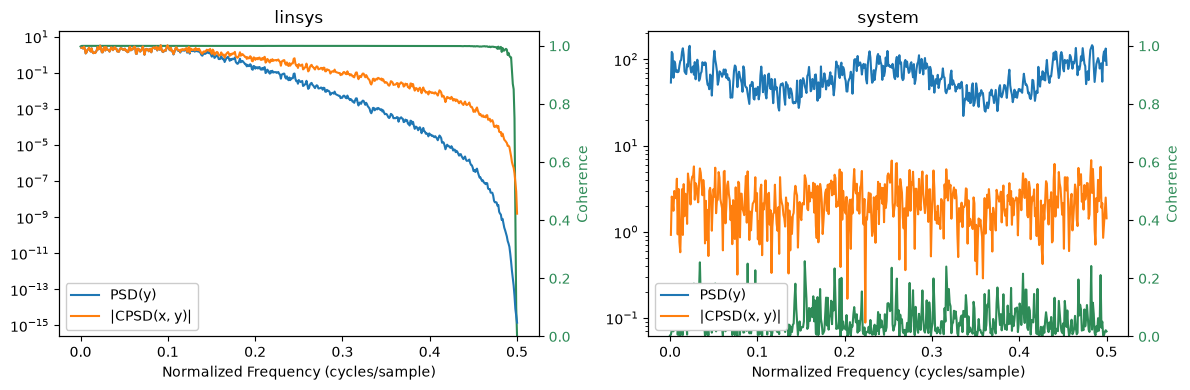

In [ ]:
n_samples = int(1e4)
x = rng.standard_normal(n_samples)
win, win_length = 'hann', 1024

fig, axs = plt.subplots(1, 2)
for ax1, (name, y) in zip(axs, {'linsys': linsys(x), 'system': system(x)}.items()):
    f_psd, psd = ssig.welch(y, nperseg=win_length, window=win)
    f_csd, csd = ssig.csd(x, y, nperseg=win_length, window=win)
    f_coh, coh = ssig.coherence(x, y, nperseg=win_length, window=win)
    ax2 = ax1.twinx()
    ax1.semilogy(f_psd[1:], psd[1:], label='PSD(y)')
    ax1.semilogy(f_csd[1:], np.abs(csd)[1:], label='|CPSD(x, y)|')
    ax2.plot(f_coh, coh, 'seagreen'); ax2.set_ylim(0, 1.05)
    ax2.set_ylabel('Coherence', color='seagreen'); ax2.tick_params(axis='y', labelcolor='seagreen')
    ax1.set_xlabel('Normalized Frequency (cycles/sample)'); ax1.set_title(name)
    ax1.set_zorder(ax2.get_zorder() + 1); ax1.patch.set_visible(False)   # legend above coherence curve
    ax1.legend(loc=3, framealpha=1)
plt.tight_layout()

Coherence ≈ 1 in the passband of `linsys`, clearly below 1 for `system`.

**But coherence cannot tell noise from nonlinearity.** Below: the low-pass output $v$ = `linsys(x)` with additive noise, and followed by a cube and a square.

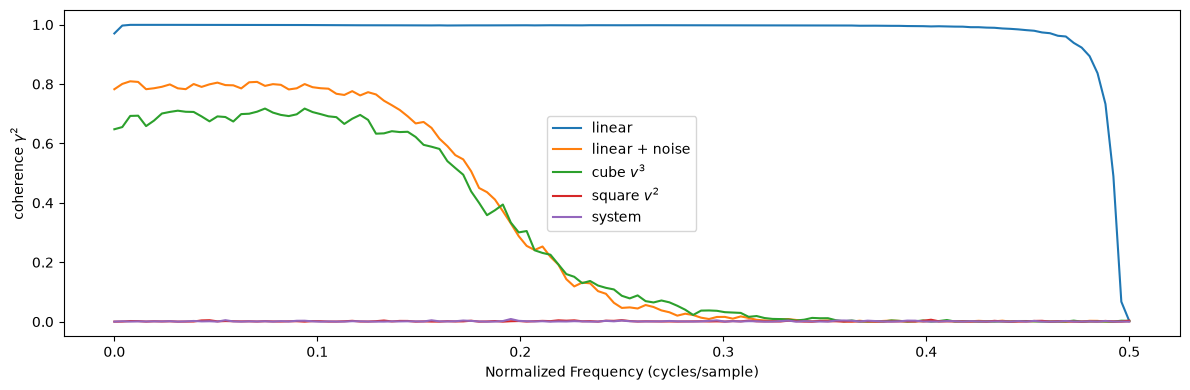

In [ ]:
N = int(1e5)
x = rng.standard_normal(N)
v = linsys(x)
outputs = {
    'linear': v,
    'linear + noise': v + 0.5 * rng.standard_normal(N),
    'cube $v^3$': v**3,
    'square $v^2$': v**2,
    'system': system(x),
}

for name, y in outputs.items():
    f, coh = ssig.coherence(x, y, nperseg=256, window='hann')
    plt.plot(f, coh, label=name)
plt.xlabel('Normalized Frequency (cycles/sample)'); plt.ylabel(r'coherence $\gamma^2$'); plt.legend(); plt.tight_layout()

Noise (≈ 0.8) and the cube (≈ 0.7) look alike. The square and `system` give ≈ 0: their output is (almost) uncorrelated with the input, although it is fully determined by it – the same effect as the zero cross-correlation in Part 1.

### Bispectrum

A nonlinearity mixes frequencies: squaring components at $f_1$ and $f_2$ creates one at $f_1+f_2$ whose phase is **locked** to the other two ($\phi_1+\phi_2$). The bispectrum
$$B(f_1,f_2) = E\{Y(f_1)\,Y(f_2)\,Y^*(f_1+f_2)\}$$
averages the triple product, whose phase is $\phi(f_1)+\phi(f_2)-\phi(f_1+f_2)$:

* **phase-coupled** → the same phase every time → the terms add up → $|B|$ large;
* **independent phases** (Gaussian noise through a linear filter) → random → they average out → $B \approx 0$.

It needs only the output, and additive noise does not create a bispectrum.

**Estimation (stingray, as in 5.1):** stingray estimates the third-order cumulant $c_3[m_1,m_2] = E\{y[n]\,y[n+m_1]\,y[n+m_2]\}$ for lags up to `max_lag`, windows it and takes the 2-D FFT.
Trade-off: a larger `max_lag` gives finer frequency resolution but a noisier estimate. With 5.1's settings ($10^4$ samples, `max_lag=256`) the estimation noise of the linear system is almost as large as the bispectrum of the square; with $10^5$ samples and `max_lag=64` the difference is about 30-fold.

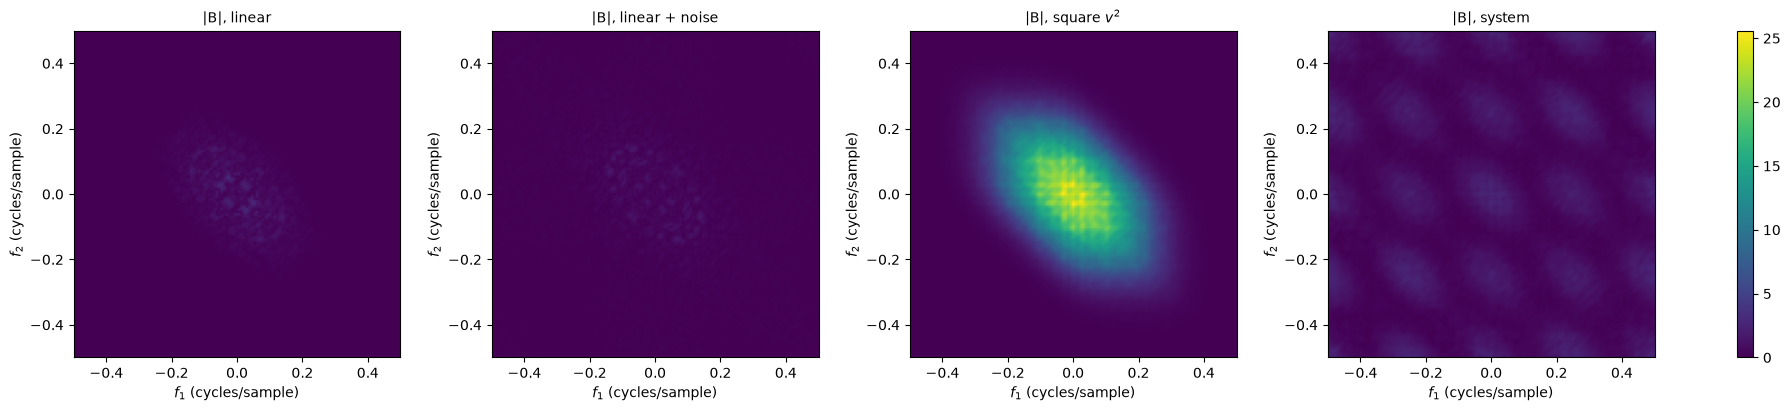

In [ ]:
plot_bispectra({k: outputs[k] for k in ['linear', 'linear + noise', 'square $v^2$', 'system']})

* **linear, linear + noise:** only weak speckle (estimation noise) – no stable structure. Rerun: the speckle changes, a real bispectrum does not.
* **square:** strong, stable structure → nonlinear.
* **system:** weaker and spread over the whole plane because the system is broadband (no low-pass), but clearly above the speckle level of the linear cases (mean $|B|$ ≈ 0.76 vs. ≈ 0.09 for `linear`).
* **Try:** the cube $v^3$. It is symmetric and couples *three* frequencies, so its bispectrum is zero although the system is nonlinear.

### Deterministic inputs: sines

A linear system keeps every sine at its frequency and only scales and shifts it ($f_s$ = 1 kHz, so 100 Hz = 0.1 cycles/sample):

* **Two unrelated sines** (100 Hz + 230 Hz): no frequency is the sum of two others → $B = 0$.
* **A sine and its harmonic** (100 Hz + 200 Hz, the input of 5.1): $200 = 100 + 100$, and both sines have a *fixed* phase relation → phase-coupled already **at the input** → a peak at $(0.1, 0.1)$ (plus its symmetric copies), **although the system is linear**.
* **One sine through a nonlinearity** $y = x + 0.5x^2$: the square creates the harmonic → the same peaks, now caused by the system.

The bispectrum detects phase coupling **in the signal**. It indicates a nonlinear system only if the input has none – which is why we use Gaussian noise as input for system analysis.

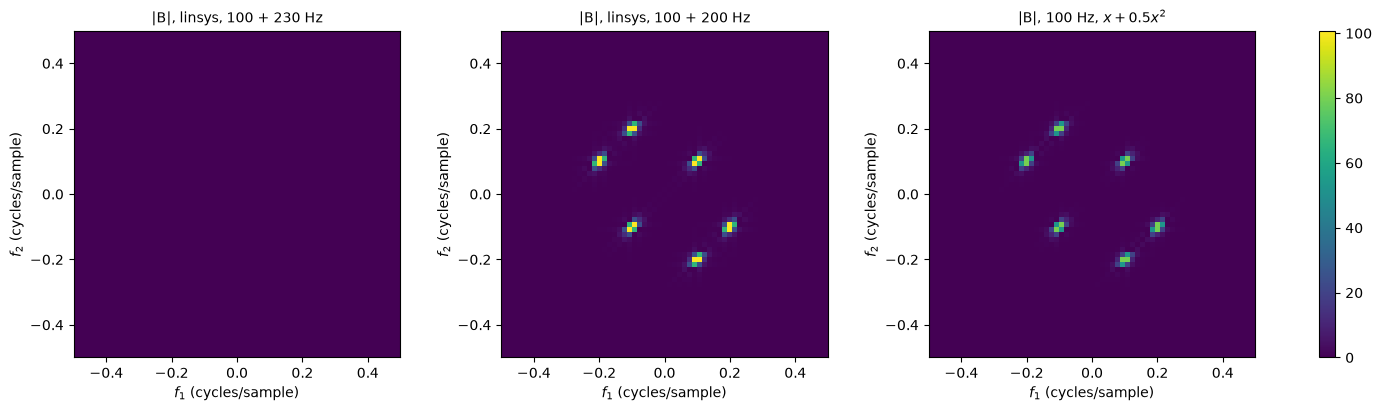

In [ ]:
n = np.arange(int(1e4))
fs = 1000
sine = lambda f: np.sin(2 * np.pi * f * n / fs)
plot_bispectra({
    'linsys, 100 + 230 Hz': linsys(sine(100) + sine(230)),
    'linsys, 100 + 200 Hz': linsys(sine(100) + sine(200)),
    '100 Hz, $x + 0.5x^2$': sine(100) + 0.5*sine(100)**2,
}, max_lag=32)                                        # short max_lag -> coarse resolution -> visible peaks